In [1]:
# ---------- CELL 1: imports and version check ----------

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Draw charts inside the notebook, not in a separate window.
%matplotlib inline

# Print the versions, so we know everything is installed correctly.
# Better to find a problem NOW than 20 minutes into training.
print("pandas     :", pd.__version__)
print("numpy      :", np.__version__)

# Check PyTorch separately. It is the biggest library,
# and the most likely to be missing.
try:
    import torch
    print("torch      :", torch.__version__)
    print("Using CPU  :", not torch.cuda.is_available())
except ImportError:
    print("torch      : NOT INSTALLED")
    print("   Install it with:")
    print("   pip install torch --index-url https://download.pytorch.org/whl/cpu")

import sklearn
print("scikit-learn:", sklearn.__version__)

print()
print("Setup complete.")

Matplotlib is building the font cache; this may take a moment.


pandas     : 3.0.6
numpy      : 2.5.3


torch      : 2.14.1+cpu
Using CPU  : True


scikit-learn: 1.9.1

Setup complete.


In [2]:
# ---------- CELL 2: load the dataset ----------

DATA_DIR = "data"
data = pd.read_csv(os.path.join(DATA_DIR, "training_data.csv"))

DATA_SOURCE = "GENERATED from Sri Lankan agronomic requirement values"

print("Rows     :", len(data))
print("Crops    :", data["crop"].nunique())
print("Features : soil_n, soil_p, soil_k, soil_ph, crop, stage, target_yield, zone")
print("Labels   : need_n, need_p, need_k")
print()
print(data.head())

Rows     : 3000
Crops    : 10
Features : soil_n, soil_p, soil_k, soil_ph, crop, stage, target_yield, zone
Labels   : need_n, need_p, need_k

   soil_n  soil_p  soil_k  soil_ph     crop       stage  target_yield zone  \
0    64.0    13.6    38.9     4.83   potato    seedling         13.13  wet   
1    50.1    12.2   213.3     7.09  coconut    maturity          8.49  dry   
2    64.0    11.1    77.3     5.66   potato    seedling         18.85  wet   
3    47.1     8.2    79.8     4.89     rice  vegetative          6.13  wet   
4    27.6    20.0   103.1     6.51   tomato  vegetative         20.67  dry   

   need_n  need_p  need_k  
0   12.66   10.09   16.97  
1    2.68    2.40    1.14  
2   18.89   13.37   24.31  
3   68.89   16.44   17.61  
4   50.30   20.37   29.70  


In [3]:
# ---------- CELL 3: look at the data ----------

print("=" * 55)
print("FIRST 5 ROWS")
print("=" * 55)
print(data.head())

print()
print("=" * 55)
print("SIZE")
print("=" * 55)
print("Rows    :", data.shape[0])
print("Columns :", data.shape[1])

print()
print("=" * 55)
print("COLUMN TYPES AND MISSING VALUES")
print("=" * 55)
data.info()

print()
print("=" * 55)
print("WHICH CROPS ARE IN THE DATA")
print("=" * 55)
# value_counts() counts how many rows each crop has.
print(data["crop"].value_counts())

FIRST 5 ROWS
   soil_n  soil_p  soil_k  soil_ph     crop       stage  target_yield zone  \
0    64.0    13.6    38.9     4.83   potato    seedling         13.13  wet   
1    50.1    12.2   213.3     7.09  coconut    maturity          8.49  dry   
2    64.0    11.1    77.3     5.66   potato    seedling         18.85  wet   
3    47.1     8.2    79.8     4.89     rice  vegetative          6.13  wet   
4    27.6    20.0   103.1     6.51   tomato  vegetative         20.67  dry   

   need_n  need_p  need_k  
0   12.66   10.09   16.97  
1    2.68    2.40    1.14  
2   18.89   13.37   24.31  
3   68.89   16.44   17.61  
4   50.30   20.37   29.70  

SIZE
Rows    : 3000
Columns : 11

COLUMN TYPES AND MISSING VALUES
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   soil_n        3000 non-null   float64
 1   soil_p        3000 non-null   float64
 2   soil_k    

In [4]:
# ---------- CELL 4: statistics ----------

print("=" * 70)
print("STATISTICS FOR EVERY NUMBER COLUMN")
print("=" * 70)

# .describe() gives count, mean, std, min, 25%, 50%, 75%, max
# .round(2) keeps it readable.
print(data.describe().round(2))

print()
print("=" * 70)
print("CHECKS")
print("=" * 70)

# CHECK 1: is any column completely flat?
# If std is 0, every value is the same, and the column is useless.
for col in data.select_dtypes(include=[np.number]).columns:
    std = data[col].std()
    if std < 0.0001:
        print(f"  PROBLEM: '{col}' never changes (std = {std}). It is useless.")
    else:
        print(f"  OK: '{col}' varies (std = {std:.2f})")

print()

# CHECK 2: are there impossible values?
# These are the same rules we built in Phase 4.
problems = 0

if (data["soil_ph"] < 0).any() or (data["soil_ph"] > 14).any():
    print("  PROBLEM: some pH values are outside 0 to 14")
    problems += 1

for col in ["soil_n", "soil_p", "soil_k"]:
    if (data[col] < 0).any():
        print(f"  PROBLEM: some {col} values are negative")
        problems += 1

if problems == 0:
    print("  OK: no impossible values found")

STATISTICS FOR EVERY NUMBER COLUMN
        soil_n   soil_p   soil_k  soil_ph  target_yield   need_n   need_p  \
count  3000.00  3000.00  3000.00  3000.00       3000.00  3000.00  3000.00   
mean     44.29    12.78    97.50     6.38         14.09    31.04    10.96   
std      20.27     6.21    50.00     0.95         10.23    21.94     7.53   
min       2.00     1.00     5.00     3.80          1.17     0.00     1.28   
25%      29.80     8.20    61.18     5.70          4.64    14.58     5.25   
50%      42.90    12.70    92.30     6.39         12.54    25.56     8.98   
75%      57.20    17.00   130.40     7.09         21.42    41.55    14.72   
max     124.70    35.90   284.60     8.80         49.25   137.84    55.00   

        need_k  
count  3000.00  
mean     20.75  
std      26.95  
min       0.00  
25%       4.41  
50%      12.15  
75%      26.67  
max     195.04  

CHECKS
  OK: 'soil_n' varies (std = 20.27)
  OK: 'soil_p' varies (std = 6.21)
  OK: 'soil_k' varies (std = 50.00)
  O

In [5]:
# ---------- CELL 6: check the labels ----------

label_cols = ["need_n", "need_p", "need_k"]

print("=" * 70)
print("LABEL STATISTICS")
print("=" * 70)
print(data[label_cols].describe().round(2))

print()
print("=" * 70)
print("CHECKS")
print("=" * 70)

for col in label_cols:
    values = data[col]

    # How many rows are exactly zero?
    zero_count = (values == 0).sum()
    zero_percent = 100 * zero_count / len(values)

    print(f"\n{col}:")
    print(f"  range   : {values.min():.1f} to {values.max():.1f}")
    print(f"  average : {values.mean():.1f}")
    print(f"  spread  : {values.std():.1f}")
    print(f"  zeros   : {zero_count} rows ({zero_percent:.1f}%)")

    # ----- The important checks -----
    if values.std() < 0.01:
        print("  PROBLEM: this label never changes. Nothing to learn.")
    elif zero_percent > 80:
        print("  PROBLEM: over 80% are zero.")
        print("           The model will just learn to always predict 0.")
    elif zero_percent > 50:
        print("  WARNING: over half are zero. Watch this during training.")
    else:
        print("  OK: good variation to learn from.")

LABEL STATISTICS
        need_n   need_p   need_k
count  3000.00  3000.00  3000.00
mean     31.04    10.96    20.75
std      21.94     7.53    26.95
min       0.00     1.28     0.00
25%      14.58     5.25     4.41
50%      25.56     8.98    12.15
75%      41.55    14.72    26.67
max     137.84    55.00   195.04

CHECKS

need_n:
  range   : 0.0 to 137.8
  average : 31.0
  spread  : 21.9
  zeros   : 1 rows (0.0%)
  OK: good variation to learn from.

need_p:
  range   : 1.3 to 55.0
  average : 11.0
  spread  : 7.5
  zeros   : 0 rows (0.0%)
  OK: good variation to learn from.

need_k:
  range   : 0.0 to 195.0
  average : 20.7
  spread  : 27.0
  zeros   : 298 rows (9.9%)
  OK: good variation to learn from.


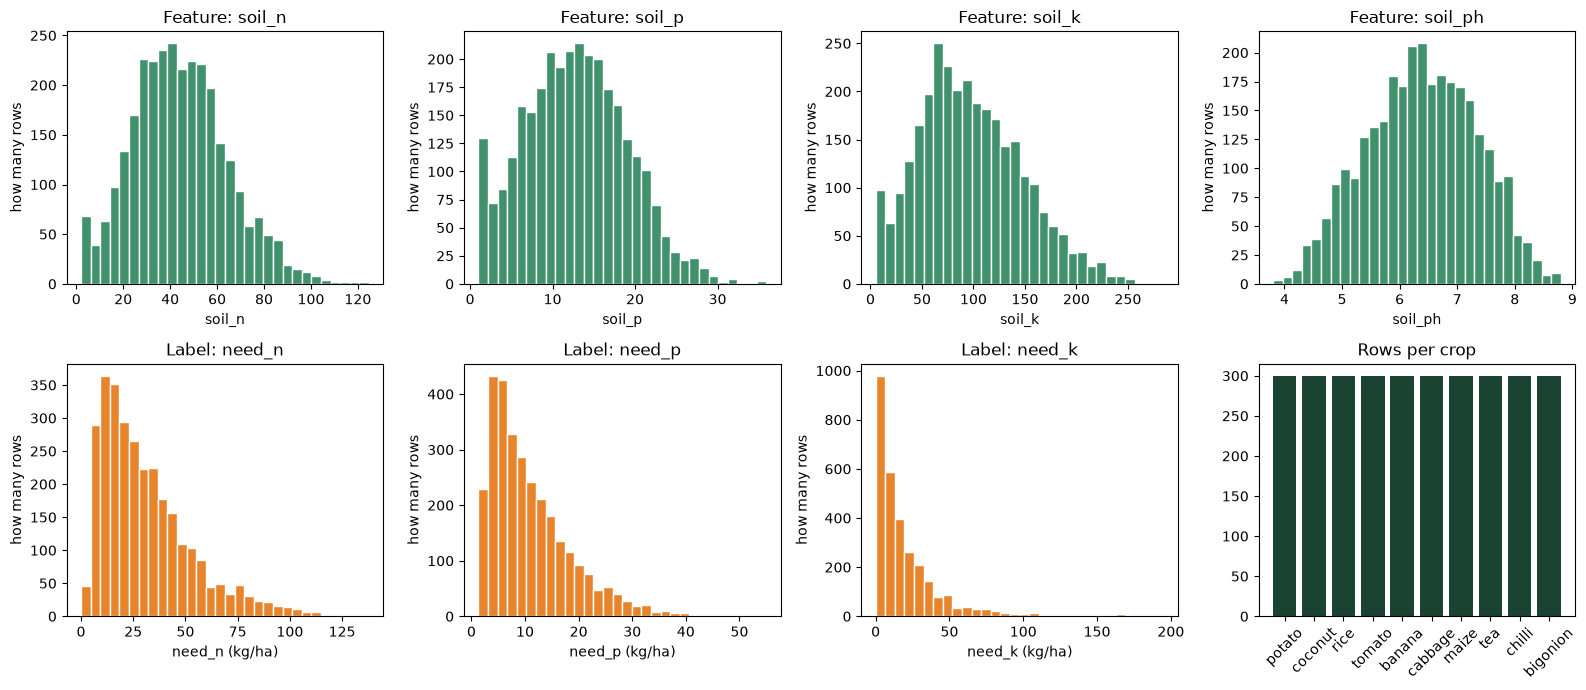


What to look for:
  GOOD : a hill shape, spread out
  BAD  : one tall bar at zero and nothing else
  BAD  : everything squeezed into one narrow spike


In [6]:
# ---------- CELL 7: draw charts ----------
#
# Numbers tell you facts. Charts show you the SHAPE.
# Your eyes find problems that numbers hide.

# One figure with 8 small charts. Easier on memory than 8 separate figures.
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

# ----- Top row: the FEATURES (what the model sees) -----
feature_cols = ["soil_n", "soil_p", "soil_k", "soil_ph"]

for i, col in enumerate(feature_cols):
    axes[0, i].hist(data[col], bins=30, color="#40916c", edgecolor="white")
    axes[0, i].set_title(f"Feature: {col}")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("how many rows")

# ----- Bottom row: the LABELS (what the model must predict) -----
for i, col in enumerate(label_cols):
    axes[1, i].hist(data[col], bins=30, color="#e8842c", edgecolor="white")
    axes[1, i].set_title(f"Label: {col}")
    axes[1, i].set_xlabel(col + " (kg/ha)")
    axes[1, i].set_ylabel("how many rows")

# ----- The last box: how many rows per crop -----
crop_counts = data["crop"].value_counts()
axes[1, 3].bar(crop_counts.index, crop_counts.values, color="#1b4332")
axes[1, 3].set_title("Rows per crop")
axes[1, 3].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Free the memory. Important on an 8GB laptop.
plt.close(fig)

print()
print("What to look for:")
print("  GOOD : a hill shape, spread out")
print("  BAD  : one tall bar at zero and nothing else")
print("  BAD  : everything squeezed into one narrow spike")

In [7]:
# ---------- CELL 8: clean and save ----------

rows_before = len(data)
print("Rows before cleaning:", rows_before)
print()

# ---------- STEP 1: remove rows with missing values ----------
# dropna() removes any row that has an empty value anywhere.
data_clean = data.dropna()
removed_missing = rows_before - len(data_clean)
print(f"Removed {removed_missing} rows with missing values")

# ---------- STEP 2: remove impossible values ----------
# These are the same rules as Phase 4.
before = len(data_clean)

data_clean = data_clean[
    (data_clean["soil_ph"] >= 0) & (data_clean["soil_ph"] <= 14) &
    (data_clean["soil_n"] >= 0) &
    (data_clean["soil_p"] >= 0) &
    (data_clean["soil_k"] >= 0) &
    (data_clean["target_yield"] > 0)
]

removed_impossible = before - len(data_clean)
print(f"Removed {removed_impossible} rows with impossible values")

# ---------- Report ----------
rows_after = len(data_clean)
percent_kept = 100 * rows_after / rows_before

print()
print("=" * 55)
print("CLEANING RESULT")
print("=" * 55)
print(f"Before : {rows_before}")
print(f"After  : {rows_after}")
print(f"Kept   : {percent_kept:.1f}%")

# NEVER remove data silently. Always check how much you lost.
if percent_kept < 90:
    print()
    print("WARNING: you removed more than 10% of the data.")
    print("         Go back and check what is wrong with it.")

# ---------- STEP 3: save it ----------
OUT_FILE = os.path.join(DATA_DIR, "training_data.csv")

# index=False stops Pandas adding an extra unnamed column.
data_clean.to_csv(OUT_FILE, index=False)

print()
print("Saved to:", OUT_FILE)
print("Part 2 will load this file. You do not need to rebuild it.")
print()
print("Data source was:", DATA_SOURCE)

Rows before cleaning: 3000

Removed 0 rows with missing values
Removed 0 rows with impossible values

CLEANING RESULT
Before : 3000
After  : 3000
Kept   : 100.0%

Saved to: data\training_data.csv
Part 2 will load this file. You do not need to rebuild it.

Data source was: GENERATED from Sri Lankan agronomic requirement values
